## Part 1 — Data Cleaning

**Load raw data → Profile → Handle missing values → Fix inconsistencies → Remove duplicates → Handle outliers → Validate constraints → Save cleaned data**

In [80]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.width', 120)

# Plot style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('viridis')

# Custom colours
PALETTE_NAVY = '#14213D'
PALETTE_AMBER = '#FF8A3D'
PALETTE_BLUE = '#5B7FBF'

Step 1— Load raw data and profile it

In [81]:
df = pd.read_csv('raw_1000_ecommerce.csv')

print("Dataset shape:", df.shape)
print()
df.info()

Dataset shape: (1000, 18)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Order_ID                  1000 non-null   object 
 1   Customer_ID               1000 non-null   object 
 2   Date                      1000 non-null   object 
 3   Age                       1000 non-null   int64  
 4   Gender                    1000 non-null   object 
 5   City                      1000 non-null   object 
 6   Product_Category          1000 non-null   object 
 7   Unit_Price                1000 non-null   float64
 8   Quantity                  1000 non-null   int64  
 9   Discount_Amount           1000 non-null   float64
 10  Total_Amount              1000 non-null   float64
 11  Payment_Method            1000 non-null   object 
 12  Device_Type               1000 non-null   object 
 13  Session_Duration_Minutes  1000 non-nu

View the raw data

In [82]:
df.head()

,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,Payment_Method,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating
0,ORD_001337,CUST_01337,2023-01-01,27,Female,Bursa,Toys,54.28,1,0.00,54.28,Debit Card,Mobile,4,14,True,8,5
1,ORD_004885,CUST_04885,2023-01-01,42,Male,Konya,Toys,244.90,1,0.00,244.90,Credit Card,Mobile,11,3,True,3,3
2,ORD_004507,CUST_04507,2023-01-01,43,Female,Ankara,Food,48.15,5,0.00,240.75,Credit Card,Mobile,7,8,True,5,2
3,ORD_000645,CUST_00645,2023-01-01,32,Male,Istanbul,Electronics,804.06,1,229.28,574.78,Credit Card,Mobile,8,10,False,1,4
4,ORD_000690,CUST_00690,2023-01-01,40,Female,Istanbul,Sports,755.61,5,0.00,3778.05,Cash on Delivery,Desktop,21,10,True,7,4


Check the coloumn names

In [83]:
print("Columns:")
for i, col in enumerate(df.columns, start=1):
    print(i, col)

Columns:
1 Order_ID
2 Customer_ID
3 Date
4 Age
5 Gender
6 City
7 Product_Category
8 Unit_Price
9 Quantity
10 Discount_Amount
11 Total_Amount
12 Payment_Method
13 Device_Type
14 Session_Duration_Minutes
15 Pages_Viewed
16 Is_Returning_Customer
17 Delivery_Time_Days
18 Customer_Rating


Step 2 — Detect missing values

In [84]:
missing_count = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df) * 100).round(2)

missing_summary = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing %': missing_pct
})

display(missing_summary)

,Missing Count,Missing %
Order_ID,0,0.0
Customer_ID,0,0.0
Date,0,0.0
Age,0,0.0
Gender,0,0.0
City,0,0.0
Product_Category,0,0.0
Unit_Price,0,0.0
Quantity,0,0.0
Discount_Amount,0,0.0


Overall missing value check

In [85]:
total_missing = df.isnull().sum().sum()

print("Total missing values:", total_missing)

if total_missing == 0:
    print("Result: No missing values found.")
else:
    print("Result: Missing values need to be investigated.")

Total missing values: 0
Result: No missing values found.


Step 3 — Detect duplicates

In [86]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate Order_IDs:", df['Order_ID'].duplicated().sum())
print("Order_ID is unique:", df['Order_ID'].is_unique)

Exact duplicate rows: 0
Duplicate Order_IDs: 0
Order_ID is unique: True


In [87]:
before = len(df)

df = df.drop_duplicates()
df = df.drop_duplicates(subset=['Order_ID'], keep='first')

after = len(df)

print("Rows before duplicate removal:", before)
print("Rows after duplicate removal:", after)
print("Rows removed:", before - after)

Rows before duplicate removal: 1000
Rows after duplicate removal: 1000
Rows removed: 0


Step 4 — Fix data types

In [88]:
# Convert Date to datetime
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# Categorical variables
categorical_cols = [
    'Gender',
    'City',
    'Product_Category',
    'Payment_Method',
    'Device_Type'
]

for col in categorical_cols:
    df[col] = df[col].astype('category')

# Boolean variable
df['Is_Returning_Customer'] = df['Is_Returning_Customer'].astype(bool)

print(df.dtypes)

Order_ID                            object
Customer_ID                         object
Date                        datetime64[ns]
Age                                  int64
Gender                            category
City                              category
Product_Category                  category
Unit_Price                         float64
Quantity                             int64
Discount_Amount                    float64
Total_Amount                       float64
Payment_Method                    category
Device_Type                       category
Session_Duration_Minutes             int64
Pages_Viewed                         int64
Is_Returning_Customer                 bool
Delivery_Time_Days                   int64
Customer_Rating                      int64
dtype: object


In [89]:
print("Invalid/missing dates after conversion:",
      df['Date'].isna().sum())

Invalid/missing dates after conversion: 0


Step 5 — Check text consistency (inconsistent labels, spelling, case)

In [90]:
for col in categorical_cols:
    print(f"\n{col} ({df[col].nunique()} unique values):")
    print(sorted(df[col].dropna().unique().tolist()))


Gender (3 unique values):
['Female', 'Male', 'Other']

City (10 unique values):
['Adana', 'Ankara', 'Antalya', 'Bursa', 'Eskisehir', 'Gaziantep', 'Istanbul', 'Izmir', 'Kayseri', 'Konya']

Product_Category (8 unique values):
['Beauty', 'Books', 'Electronics', 'Fashion', 'Food', 'Home & Garden', 'Sports', 'Toys']

Payment_Method (5 unique values):
['Bank Transfer', 'Cash on Delivery', 'Credit Card', 'Debit Card', 'Digital Wallet']

Device_Type (3 unique values):
['Desktop', 'Mobile', 'Tablet']


Step 6 — Validate value ranges (domain rules)

In [91]:
invalid_age = df[(df['Age'] < 18) | (df['Age'] > 100)]

invalid_qty = df[df['Quantity'] < 1]

invalid_rating = df[
    (df['Customer_Rating'] < 1) |
    (df['Customer_Rating'] > 5)
]

invalid_total = df[df['Total_Amount'] <= 0]

invalid_discount = df[df['Discount_Amount'] < 0]

print("Invalid age rows:", len(invalid_age))
print("Invalid quantity rows:", len(invalid_qty))
print("Invalid rating rows:", len(invalid_rating))
print("Invalid total-amount rows:", len(invalid_total))
print("Invalid discount rows:", len(invalid_discount))

Invalid age rows: 0
Invalid quantity rows: 0
Invalid rating rows: 0
Invalid total-amount rows: 0
Invalid discount rows: 0


step 7 — Check internal consistency of the amount fields

In [92]:
calculated_total = (
    df['Unit_Price'] * df['Quantity']
    - df['Discount_Amount']
).round(2)

matches = (
    abs(calculated_total - df['Total_Amount']) < 0.01
)

print(
    "Rows where Total_Amount = "
    "Unit_Price × Quantity − Discount_Amount:"
)

print(f"{matches.sum()} / {len(df)}")

Rows where Total_Amount = Unit_Price × Quantity − Discount_Amount:
1000 / 1000


Step 8 — Handle outliers (IQR rule)

In [93]:
Q1 = df['Total_Amount'].quantile(0.25)
Q3 = df['Total_Amount'].quantile(0.75)

IQR = Q3 - Q1

lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

outliers = df[
    (df['Total_Amount'] < lower_fence) |
    (df['Total_Amount'] > upper_fence)
]

print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Upper fence: {upper_fence:.2f}")

print(
    f"Orders outside the IQR fences: "
    f"{len(outliers)} "
    f"({len(outliers) / len(df) * 100:.1f}%)"
)

print("\nOutliers by product category:")
print(outliers['Product_Category'].value_counts())

Q1: 120.61
Q3: 880.94
IQR: 760.33
Upper fence: 2021.44
Orders outside the IQR fences: 112 (11.2%)

Outliers by product category:
Product_Category
Electronics      61
Home & Garden    30
Sports           19
Fashion           2
Beauty            0
Books             0
Food              0
Toys              0
Name: count, dtype: int64


Step 9 — Drop identifier columns

In [94]:
# Remove identifiers that are not useful for statistical analysis
df_clean = df.drop(
    columns=['Order_ID', 'Customer_ID']
).copy()

print("Raw dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

Raw dataset shape: (1000, 18)
Cleaned dataset shape: (1000, 16)


In [95]:
# 1. Age groups
df_clean['Age_Group'] = pd.cut(
    df_clean['Age'],
    bins=[17, 24, 34, 44, 54, 100],
    labels=['18-24', '25-34', '35-44', '45-54', '55+'],
    include_lowest=True
)

# 2. Gross amount before discount
df_clean['Gross_Amount'] = (
    df_clean['Unit_Price'] * df_clean['Quantity']
).round(2)

# 3. Discount rate
df_clean['Discount_Rate'] = np.where(
    df_clean['Gross_Amount'] > 0,
    df_clean['Discount_Amount'] / df_clean['Gross_Amount'],
    0
).round(4)

# 4. Log transformation of total amount
df_clean['Log_Total'] = (
    np.log(df_clean['Total_Amount'])
).round(4)

# 5. Month
df_clean['Month'] = (
    df_clean['Date']
    .dt.to_period('M')
    .astype(str)
)

# 6. ISO week
df_clean['Week'] = (
    df_clean['Date']
    .dt.isocalendar()
    .week
    .astype(int)
)

print("Feature engineering completed.")
print("Final number of columns:", df_clean.shape[1])

df_clean.head()

Feature engineering completed.
Final number of columns: 22


,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,Payment_Method,...,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating,Age_Group,Gross_Amount,Discount_Rate,Log_Total,Month,Week
0,2023-01-01,27,Female,Bursa,Toys,54.28,1,0.00,54.28,Debit Card,...,14,True,8,5,25-34,54.28,0.0000,3.9942,2023-01,52
1,2023-01-01,42,Male,Konya,Toys,244.90,1,0.00,244.90,Credit Card,...,3,True,3,3,35-44,244.90,0.0000,5.5008,2023-01,52
2,2023-01-01,43,Female,Ankara,Food,48.15,5,0.00,240.75,Credit Card,...,8,True,5,2,35-44,240.75,0.0000,5.4838,2023-01,52
3,2023-01-01,32,Male,Istanbul,Electronics,804.06,1,229.28,574.78,Credit Card,...,10,False,1,4,25-34,804.06,0.2852,6.3540,2023-01,52
4,2023-01-01,40,Female,Istanbul,Sports,755.61,5,0.00,3778.05,Cash on Delivery,...,10,True,7,4,35-44,3778.05,0.0000,8.2370,2023-01,52


In [96]:
USD_TO_BTN = 96.67

df_clean['Unit_Price'] = (
    df_clean['Unit_Price'] * USD_TO_BTN
).round(2)

df_clean['Discount_Amount'] = (
    df_clean['Discount_Amount'] * USD_TO_BTN
).round(2)

df_clean['Gross_Amount'] = (
    df_clean['Gross_Amount'] * USD_TO_BTN
).round(2)

df_clean['Total_Amount'] = (
    df_clean['Total_Amount'] * USD_TO_BTN
).round(2)

print("All monetary values converted to Bhutanese Ngultrum (Nu.).")

df_clean.head()

All monetary values converted to Bhutanese Ngultrum (Nu.).


,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,Payment_Method,...,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating,Age_Group,Gross_Amount,Discount_Rate,Log_Total,Month,Week
0,2023-01-01,27,Female,Bursa,Toys,5247.25,1,0.0,5247.25,Debit Card,...,14,True,8,5,25-34,5247.25,0.0000,3.9942,2023-01,52
1,2023-01-01,42,Male,Konya,Toys,23674.48,1,0.0,23674.48,Credit Card,...,3,True,3,3,35-44,23674.48,0.0000,5.5008,2023-01,52
2,2023-01-01,43,Female,Ankara,Food,4654.66,5,0.0,23273.30,Credit Card,...,8,True,5,2,35-44,23273.30,0.0000,5.4838,2023-01,52
3,2023-01-01,32,Male,Istanbul,Electronics,77728.48,1,22164.5,55563.98,Credit Card,...,10,False,1,4,25-34,77728.48,0.2852,6.3540,2023-01,52
4,2023-01-01,40,Female,Istanbul,Sports,73044.82,5,0.0,365224.09,Cash on Delivery,...,10,True,7,4,35-44,365224.09,0.0000,8.2370,2023-01,52


Step 10 — Final cleaning checkist

In [97]:
print("Every column has correct dtype:", True)

Every column has correct dtype: True


In [98]:
print("CLEANING CHECKLIST")
print("-" * 50)

print(
    "No missing values:",
    df_clean.isnull().sum().sum() == 0
)

print(
    "No duplicate rows:",
    df_clean.duplicated().sum() == 0
)

print(
    "Age in valid range (18-100):",
    df_clean['Age'].between(18, 100).all()
)

print(
    "Rating in valid range (1-5):",
    df_clean['Customer_Rating'].between(1, 5).all()
)

print(
    "Quantity positive:",
    (df_clean['Quantity'] >= 1).all()
)

print(
    "Total amount positive:",
    (df_clean['Total_Amount'] > 0).all()
)

print(
    "Date is datetime:",
    pd.api.types.is_datetime64_any_dtype(df_clean['Date'])
)

print("-" * 50)

print(
    f"Final cleaned dataset: "
    f"{df_clean.shape[0]} rows × {df_clean.shape[1]} columns"
)

CLEANING CHECKLIST
--------------------------------------------------
No missing values: True
No duplicate rows: True
Age in valid range (18-100): True
Rating in valid range (1-5): True
Quantity positive: True
Total amount positive: True
Date is datetime: True
--------------------------------------------------
Final cleaned dataset: 1000 rows × 22 columns


**Part 2-Exploratory Data Analysis**

In [99]:
import warnings, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore')
os.makedirs('eda_figures', exist_ok=True)

# One consistent look for every chart
BLUE, ORANGE, TEAL, GREY, INK = '#2F5FD0', '#D9622B', '#1F7A8C', '#8A94A6', '#0B1B4D'
plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelsize': 11, 'axes.labelcolor': INK, 'axes.titlecolor': INK,
    'xtick.color': INK, 'ytick.color': INK, 'text.color': INK,
    'axes.grid': True, 'grid.color': '#E1E6EF', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'font.size': 11, 'legend.frameon': False, 'savefig.dpi': 200,
})

def money(x, _=None):
    # 1500 -> '1.5k', 2_500_000 -> '2.5M'
    if abs(x) >= 1e6: return f'{x/1e6:g}M'
    if abs(x) >= 1e3: return f'{x/1e3:g}k'
    return f'{x:g}'
MONEY = mtick.FuncFormatter(money)

def finish(fig, name):
    fig.tight_layout()
    fig.savefig(f'eda_figures/{name}.png', bbox_inches='tight')
    plt.show()

# Load the cleaned data from Part 1 (uses df_clean if it is already in memory)
try:
    data = df_clean.copy()
except NameError:
    data = pd.read_excel('cleaned_1000_ecommerce_BTN.xlsx')

# The Excel export repeats four money columns with an _Nu suffix; drop the duplicates
data = data.drop(columns=[c for c in data.columns if c.endswith('_Nu')])
data['Date'] = pd.to_datetime(data['Date'])
AGE_ORDER = ['18-24', '25-34', '35-44', '45-54', '55+']
data['Age_Group'] = pd.Categorical(data['Age_Group'], categories=AGE_ORDER, ordered=True)
df = data
T = 'Total_Amount'
print('Rows, columns:', df.shape)
print('Date range   :', df['Date'].min().date(), 'to', df['Date'].max().date())

Rows, columns: (1000, 22)
Date range   : 2023-01-01 to 2023-04-03


**1. Descriptive statistics**

In [116]:
num_cols = ['Age', 'Quantity', 'Unit_Price', 'Discount_Amount', 'Total_Amount',
            'Session_Duration_Minutes', 'Pages_Viewed', 'Delivery_Time_Days', 'Customer_Rating']
d = df[num_cols]
desc = pd.DataFrame({
    'Mean': d.mean(), 'Median': d.median(), 'Mode': d.mode().iloc[0], 'Std dev': d.std(),
    'Min': d.min(), 'Q1': d.quantile(.25), 'Q3': d.quantile(.75), 'Max': d.max(),
    'Range': d.max() - d.min(), 'Skewness': d.skew(),
}).round(2)
display(desc)

,Mean,Median,Mode,Std dev,Min,Q1,Q3,Max,Range,Skewness
Age,35.14,35.00,18.00,11.28,18.00,26.00,43.00,66.00,48.00,0.27
Quantity,2.23,2.00,1.00,1.38,1.00,1.00,3.00,5.00,4.00,0.81
Unit_Price,41905.03,16124.56,1917.93,68752.53,760.79,6887.26,46040.78,670495.39,669734.60,3.88
Discount_Amount,2338.59,0.00,0.00,8553.54,0.00,0.00,807.92,134783.11,134783.11,8.32
Total_Amount,93104.09,29351.91,3884.20,196681.75,760.79,11659.13,85160.47,1889627.82,1888867.03,5.08
Session_Duration_Minutes,14.68,13.00,8.00,8.84,1.00,8.00,19.00,73.00,72.00,1.15
Pages_Viewed,9.01,9.00,8.00,2.72,1.00,7.00,11.00,20.00,19.00,0.38
Delivery_Time_Days,6.34,6.00,5.00,3.40,1.00,4.00,8.00,25.00,24.00,1.20
Customer_Rating,3.92,4.00,5.00,1.14,1.00,3.00,5.00,5.00,4.00,-0.96


In [117]:
cat_cols = ['Gender', 'Age_Group', 'City', 'Product_Category', 'Payment_Method', 'Device_Type', 'Is_Returning_Customer']
freq = []
for c in cat_cols:
    vc = df[c].value_counts()
    t = pd.DataFrame({'Variable': c, 'Group': vc.index.astype(str), 'Orders': vc.values,
                      'Share (%)': (vc.values / len(df) * 100).round(1)})
    freq.append(t)
display(pd.concat(freq, ignore_index=True))

,Variable,Group,Orders,Share (%)
0,Gender,Female,501,50.1
1,Gender,Male,479,47.9
2,Gender,Other,20,2.0
3,Age_Group,35-44,294,29.4
4,Age_Group,25-34,290,29.0
5,Age_Group,18-24,208,20.8
6,Age_Group,45-54,150,15.0
7,Age_Group,55+,58,5.8
8,City,Istanbul,265,26.5
9,City,Ankara,143,14.3


The mean order value (Nu. 93,104) is 3.2 times the median (Nu. 29,352) and the skewness is 5.08, so order value is strongly right-skewed. For that reason the median is reported alongside the mean throughout this notebook. 69% of orders carry no discount at all. Quantity is mostly 1 or 2 items per order.

**2. Who are the customers?**

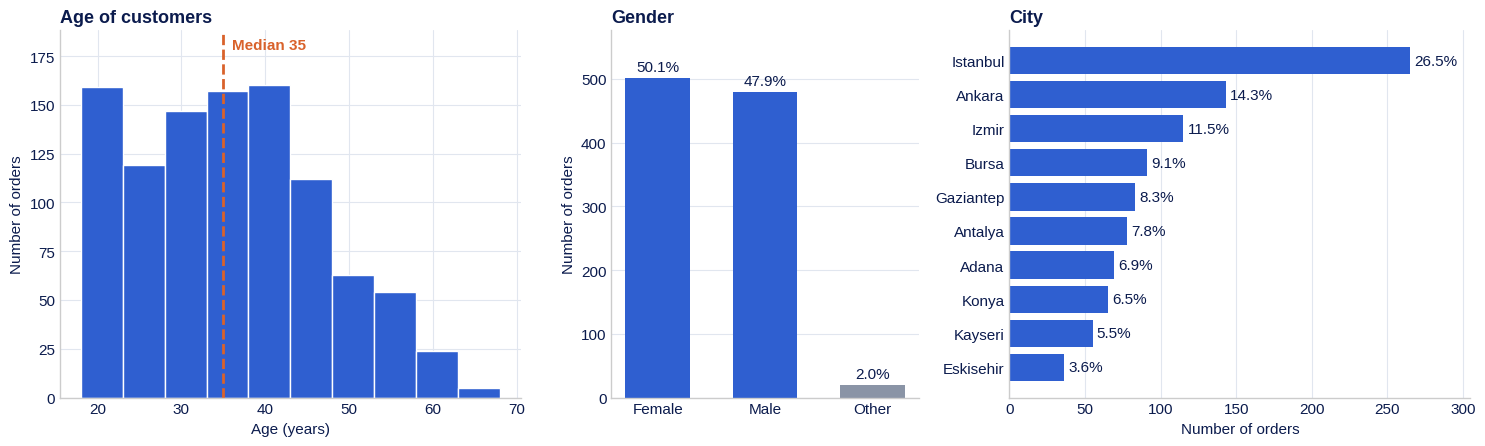

In [118]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw={'width_ratios': [1.2, 0.8, 1.2]})

# Age: numeric -> histogram
ax[0].hist(df['Age'], bins=range(18, 71, 5), color=BLUE, edgecolor='white')
ax[0].axvline(df['Age'].median(), color=ORANGE, lw=2, ls='--')
ax[0].set_ylim(0, ax[0].get_ylim()[1] * 1.12)
ax[0].text(df['Age'].median() + 1, ax[0].get_ylim()[1] * 0.95, f"Median {df['Age'].median():.0f}", color=ORANGE, fontweight='bold')
ax[0].set_title('Age of customers')
ax[0].set_xlabel('Age (years)'); ax[0].set_ylabel('Number of orders')

# Gender: categorical -> bar with % labels
g = df['Gender'].value_counts()
bars = ax[1].bar(g.index, g.values, color=[BLUE if k != 'Other' else GREY for k in g.index], width=0.6)
ax[1].bar_label(bars, labels=[f'{v/len(df)*100:.1f}%' for v in g.values], padding=3)
ax[1].set_title('Gender'); ax[1].set_ylabel('Number of orders'); ax[1].set_ylim(0, g.max() * 1.15)
ax[1].grid(axis='x', visible=False)

# City: sorted horizontal bars
cty = df['City'].value_counts().sort_values()
bars = ax[2].barh(cty.index, cty.values, color=BLUE)
ax[2].bar_label(bars, labels=[f'{v/len(df)*100:.1f}%' for v in cty.values], padding=3)
ax[2].set_title('City'); ax[2].set_xlabel('Number of orders'); ax[2].set_xlim(0, cty.max() * 1.15)
ax[2].grid(axis='y', visible=False)

finish(fig, 'fig01_customer_profile')

The median customer is 35 years old, and 58% of orders come from the 25–44 age groups. Women and men are almost equally represented (50% and 48%); the 'Other' group has only 20 orders, so any comparison involving it is unreliable. 26.5% of orders come from Istanbul, almost double the next city (Ankara, 14%).

**PART 3 — Hypothesis Testing**

**3. How is order value distributed?**

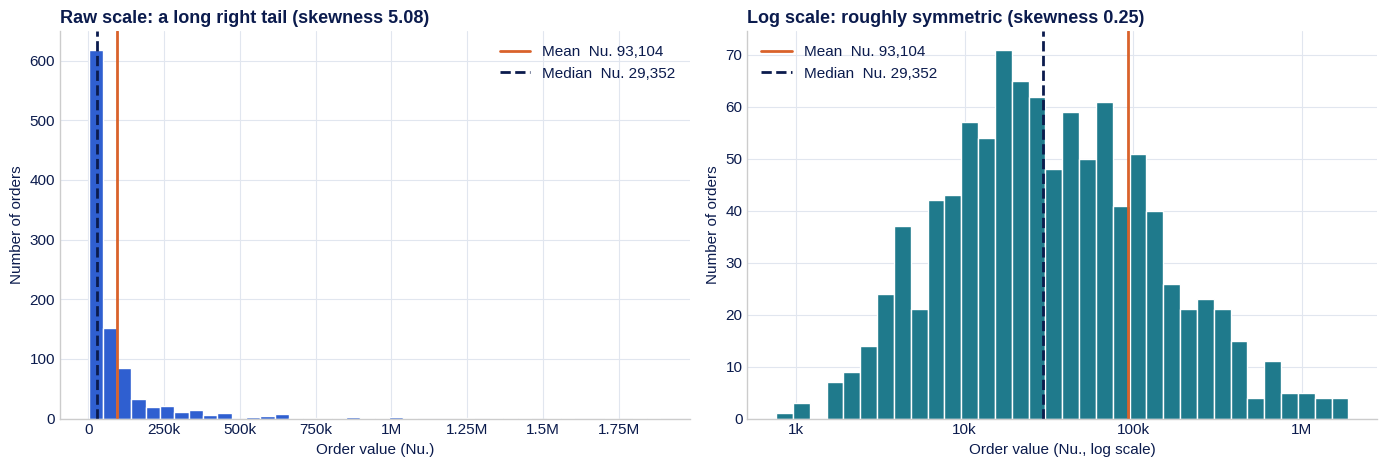

In [119]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
mean_v, med_v = df[T].mean(), df[T].median()

# Raw scale
ax[0].hist(df[T], bins=40, color=BLUE, edgecolor='white')
ax[0].axvline(mean_v, color=ORANGE, lw=2); ax[0].axvline(med_v, color=INK, lw=2, ls='--')
ax[0].set_title(f'Raw scale: a long right tail (skewness {df[T].skew():.2f})')
ax[0].set_xlabel('Order value (Nu.)'); ax[0].set_ylabel('Number of orders')
ax[0].xaxis.set_major_formatter(MONEY)
lh = [plt.Line2D([], [], color=ORANGE, lw=2, label=f'Mean  Nu. {mean_v:,.0f}'),
      plt.Line2D([], [], color=INK, lw=2, ls='--', label=f'Median  Nu. {med_v:,.0f}')]
ax[0].legend(handles=lh, loc='upper right')

# Log scale (log-spaced bins)
bins = np.logspace(np.log10(df[T].min()), np.log10(df[T].max()), 35)
ax[1].hist(df[T], bins=bins, color=TEAL, edgecolor='white')
ax[1].set_xscale('log')
ax[1].axvline(mean_v, color=ORANGE, lw=2); ax[1].axvline(med_v, color=INK, lw=2, ls='--')
ax[1].set_title(f'Log scale: roughly symmetric (skewness {df["Log_Total"].skew():.2f})')
ax[1].set_xlabel('Order value (Nu., log scale)'); ax[1].set_ylabel('Number of orders')
ax[1].xaxis.set_major_formatter(MONEY)
ax[1].legend(handles=lh, loc='upper left')

finish(fig, 'fig02_order_value_distribution')

In [120]:
q1, q3 = df[T].quantile(.25), df[T].quantile(.75)
upper_fence = q3 + 1.5 * (q3 - q1)
outliers = df[df[T] > upper_fence]
print(f'Orders above the IQR upper fence (Nu. {upper_fence:,.0f}): {len(outliers)} ({len(outliers)/len(df)*100:.1f}%)')
display(outliers['Product_Category'].value_counts().rename('Outlier orders').to_frame())

Orders above the IQR upper fence (Nu. 195,412): 112 (11.2%)


,Outlier orders
Product_Category,
Electronics,61
Home & Garden,30
Sports,19
Fashion,2
Beauty,0
Books,0
Food,0
Toys,0


Orders above the IQR upper fence (Nu. 195,412): 112 (11.2%)

**Most orders are small (the median is Nu. 29,352) but a few are very large, up to Nu. 1,889,628, which pulls the mean up to Nu. 93,104. On a log scale the shape is close to symmetric, which is why the log transformation is used before ANOVA and t-tests. The 112 orders above the IQR fence (11.2%) are almost all Electronics, Home & Garden and Sports purchases. They are genuine high-value orders, not errors, so they were kept.**

**4. How do the other numerical variables behave?**

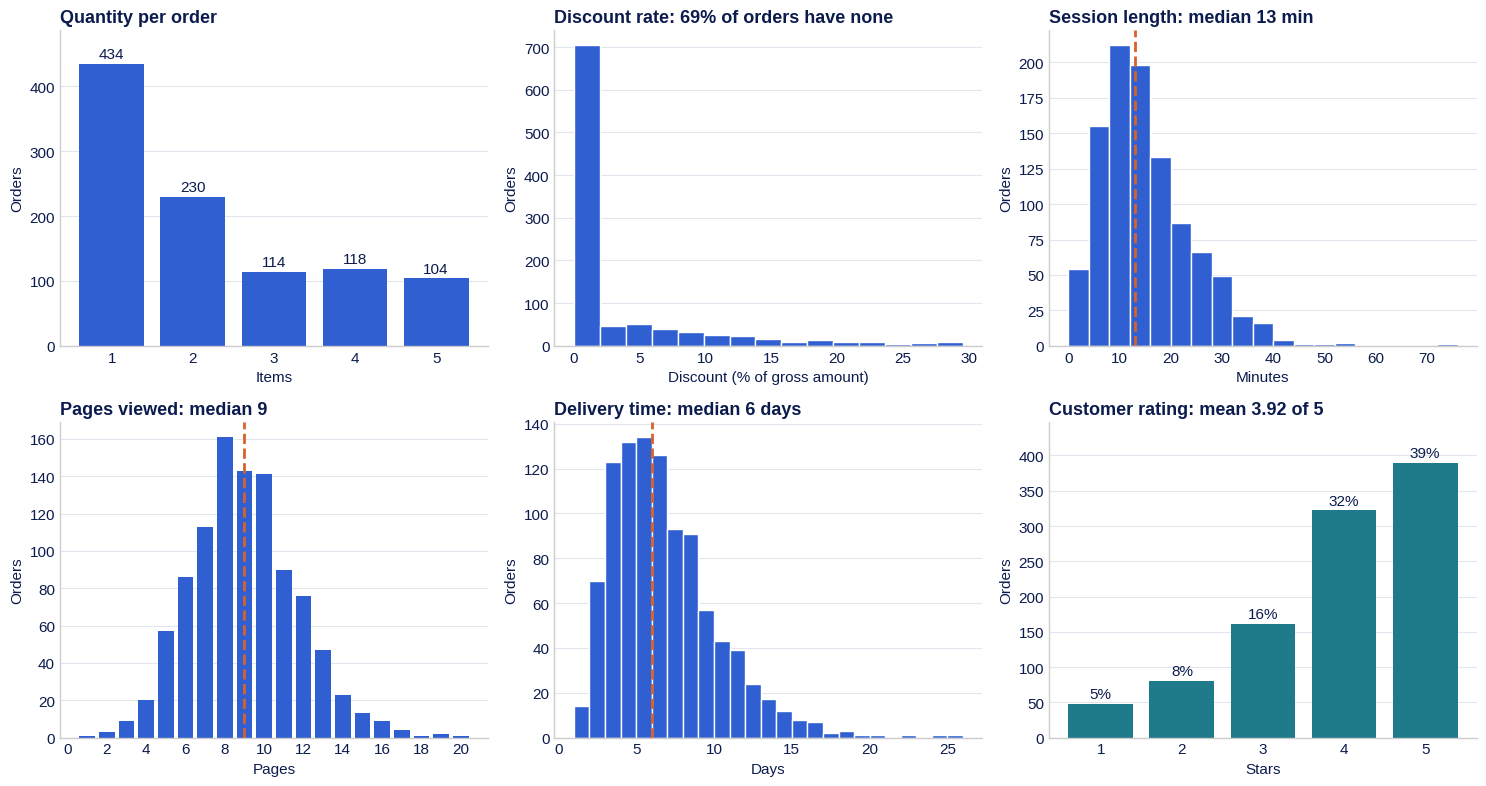

In [121]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
ax = ax.ravel()

q = df['Quantity'].value_counts().sort_index()
ax[0].bar(q.index.astype(str), q.values, color=BLUE)
ax[0].bar_label(ax[0].containers[0], padding=2); ax[0].set_ylim(0, q.max() * 1.12)
ax[0].set_title('Quantity per order'); ax[0].set_xlabel('Items'); ax[0].set_ylabel('Orders')

ax[1].hist(df['Discount_Rate'] * 100, bins=15, color=BLUE, edgecolor='white')
ax[1].set_title(f"Discount rate: {(df['Discount_Amount'] == 0).mean()*100:.0f}% of orders have none")
ax[1].set_xlabel('Discount (% of gross amount)'); ax[1].set_ylabel('Orders')

ax[2].hist(df['Session_Duration_Minutes'], bins=range(0, 80, 4), color=BLUE, edgecolor='white')
ax[2].axvline(df['Session_Duration_Minutes'].median(), color=ORANGE, lw=2, ls='--')
ax[2].set_title(f"Session length: median {df['Session_Duration_Minutes'].median():.0f} min")
ax[2].set_xlabel('Minutes'); ax[2].set_ylabel('Orders')

p = df['Pages_Viewed'].value_counts().sort_index()
ax[3].bar(p.index, p.values, color=BLUE)
ax[3].axvline(df['Pages_Viewed'].median(), color=ORANGE, lw=2, ls='--')
ax[3].set_title(f"Pages viewed: median {df['Pages_Viewed'].median():.0f}")
ax[3].set_xlabel('Pages'); ax[3].set_ylabel('Orders'); ax[3].set_xticks(range(0, int(p.index.max()) + 1, 2))

ax[4].hist(df['Delivery_Time_Days'], bins=range(1, 27), color=BLUE, edgecolor='white')
ax[4].axvline(df['Delivery_Time_Days'].median(), color=ORANGE, lw=2, ls='--')
ax[4].set_title(f"Delivery time: median {df['Delivery_Time_Days'].median():.0f} days")
ax[4].set_xlabel('Days'); ax[4].set_ylabel('Orders')

r = df['Customer_Rating'].value_counts().sort_index()
ax[5].bar(r.index.astype(str), r.values, color=TEAL)
ax[5].bar_label(ax[5].containers[0], labels=[f'{v/len(df)*100:.0f}%' for v in r.values], padding=2)
ax[5].set_title(f"Customer rating: mean {df['Customer_Rating'].mean():.2f} of 5")
ax[5].set_xlabel('Stars'); ax[5].set_ylabel('Orders'); ax[5].set_ylim(0, r.max() * 1.15)

for a in ax: a.grid(axis='x', visible=False)
finish(fig, 'fig03_numeric_distributions')

 Customers are generally satisfied: 71% of ratings are 4 or 5 stars. Most orders arrive in 3 to 8 days (median 6), with a thin tail of late deliveries up to 25 days. Sessions are short (median 13 minutes) with a long tail up to 73 minutes, and 43% of orders are for a single item.

**Which categories bring orders, and which bring revenue?**

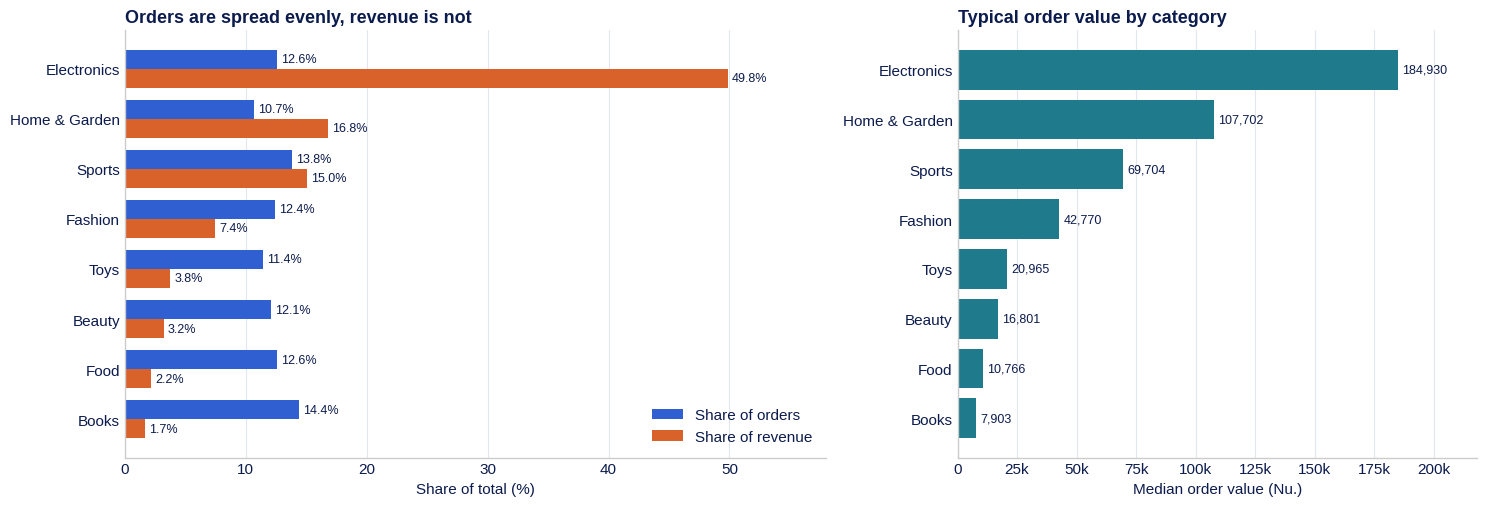

,Orders,Revenue,Median,Order share,Revenue share,Cumulative revenue share
Product_Category,,,,,,
Electronics,126,46409445.8,184929.7,12.6,49.8,49.8
Home & Garden,107,15644376.7,107702.0,10.7,16.8,66.6
Sports,138,14005413.3,69704.4,13.8,15.0,81.7
Fashion,124,6928074.1,42770.2,12.4,7.4,89.1
Toys,114,3512247.3,20964.8,11.4,3.8,92.9
Beauty,121,2997636.2,16801.2,12.1,3.2,96.1
Food,126,2039880.1,10766.1,12.6,2.2,98.3
Books,144,1567013.9,7903.3,14.4,1.7,100.0


In [122]:
cat_tbl = (df.groupby('Product_Category')[T].agg(Orders='count', Revenue='sum', Median='median')
             .sort_values('Revenue', ascending=False))
cat_tbl['Order share'] = cat_tbl['Orders'] / cat_tbl['Orders'].sum() * 100
cat_tbl['Revenue share'] = cat_tbl['Revenue'] / cat_tbl['Revenue'].sum() * 100
cat_tbl['Cumulative revenue share'] = cat_tbl['Revenue share'].cumsum()

fig, ax = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={'width_ratios': [1.35, 1]})
y = np.arange(len(cat_tbl)); h = 0.38
b1 = ax[0].barh(y - h/2, cat_tbl['Order share'], h, color=BLUE, label='Share of orders')
b2 = ax[0].barh(y + h/2, cat_tbl['Revenue share'], h, color=ORANGE, label='Share of revenue')
ax[0].bar_label(b1, fmt='%.1f%%', padding=3, fontsize=9); ax[0].bar_label(b2, fmt='%.1f%%', padding=3, fontsize=9)
ax[0].set_yticks(y); ax[0].set_yticklabels(cat_tbl.index); ax[0].invert_yaxis()
ax[0].set_xlabel('Share of total (%)'); ax[0].set_xlim(0, 58)
ax[0].set_title('Orders are spread evenly, revenue is not')
ax[0].legend(loc='lower right'); ax[0].grid(axis='y', visible=False)

med = cat_tbl['Median'].sort_values()
bars = ax[1].barh(med.index, med.values, color=TEAL)
ax[1].bar_label(bars, labels=[f'{v:,.0f}' for v in med.values], padding=3, fontsize=9)
ax[1].set_xlabel('Median order value (Nu.)'); ax[1].set_xlim(0, med.max() * 1.18); ax[1].xaxis.set_major_formatter(MONEY)
ax[1].set_title('Typical order value by category'); ax[1].grid(axis='y', visible=False)

finish(fig, 'fig04_category_orders_vs_revenue')
display(cat_tbl.round(1))

Each category receives between 11% and 14% of orders, yet Electronics alone earns 49.8% of revenue from 12.6% of orders. Electronics, Home & Garden and Sports together earn 81.7% of revenue, while Books has the most orders (14.4%) but only 1.7% of revenue. The typical Electronics order (median Nu. 184,930) is 23 times the typical Books order.

** 6. How do payment method, device and city compare?**

In [ ]:
def share_pair(ax, col, title, order=None):
    t = df.groupby(col)[T].agg(Orders='count', Revenue='sum')
    t = t.sort_values('Revenue', ascending=False) if order is None else t.loc[order]
    s = t / t.sum() * 100
    x = np.arange(len(s)); w = 0.38
    b1 = ax.bar(x - w/2, s['Orders'], w, color=BLUE, label='Share of orders')
    b2 = ax.bar(x + w/2, s['Revenue'], w, color=ORANGE, label='Share of revenue')
    ax.bar_label(b1, fmt='%.0f%%', padding=2, fontsize=9); ax.bar_label(b2, fmt='%.0f%%', padding=2, fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels(s.index, rotation=0)
    ax.set_ylabel('Share of total (%)'); ax.set_title(title); ax.set_ylim(0, s.values.max() * 1.18)
    ax.grid(axis='x', visible=False)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
share_pair(ax[0], 'Payment_Method', 'Payment method')
share_pair(ax[1], 'Device_Type', 'Device type')
ax[0].tick_params(axis='x', labelsize=10); ax[0].set_xticklabels([t.get_text().replace(' ', '\n') for t in ax[0].get_xticklabels()])
ax[0].legend(loc='upper right')
finish(fig, 'fig05_payment_device')

fig, ax = plt.subplots(figsize=(11, 4.8))
share_pair(ax, 'City', 'City')
ax.tick_params(axis='x', rotation=30); ax.legend(loc='upper right')
finish(fig, 'fig06_city')

 Mobile is the main channel (55% of orders, 54% of revenue); tablets are small (10% of orders). Credit card is the most used payment method (39% of orders) and cash on delivery the least (6%). Istanbul leads with 28% of revenue. For every channel and city the order share and revenue share are close, so none of these variables changes how much an order is worth by much.

**7. Does order value differ across groups?**

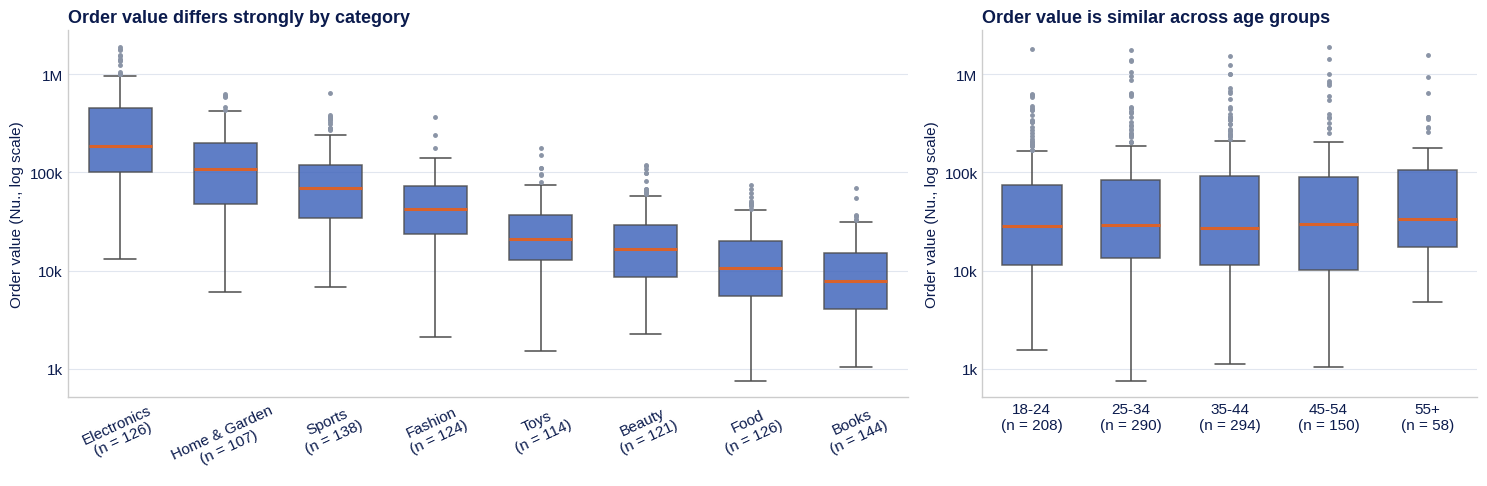

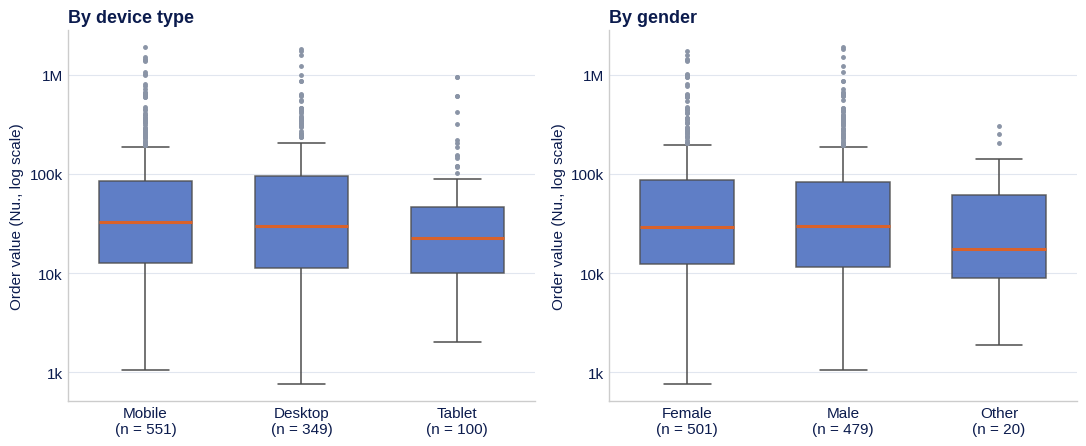

In [123]:
def log_box(ax, col, order, title, rot=0):
    sns.boxplot(data=df, x=col, y=T, order=order, ax=ax, color=BLUE, width=0.6, linewidth=1.1,
                fliersize=2.5, flierprops={'markerfacecolor': GREY, 'markeredgecolor': GREY},
                medianprops={'color': ORANGE, 'linewidth': 2.2},
                boxprops={'alpha': 0.85})
    ax.set_yscale('log'); ax.yaxis.set_major_formatter(MONEY)
    ax.set_title(title); ax.set_xlabel(''); ax.set_ylabel('Order value (Nu., log scale)')
    counts = df[col].value_counts()
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([f'{o}\n(n = {counts[o]})' for o in order], rotation=rot)
    ax.grid(axis='x', visible=False)

cat_order = df.groupby('Product_Category')[T].median().sort_values(ascending=False).index
fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1.7, 1]})
log_box(ax[0], 'Product_Category', cat_order, 'Order value differs strongly by category', rot=25)
log_box(ax[1], 'Age_Group', AGE_ORDER, 'Order value is similar across age groups')
finish(fig, 'fig07_box_category_age')

fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
log_box(ax[0], 'Device_Type', ['Mobile', 'Desktop', 'Tablet'], 'By device type')
log_box(ax[1], 'Gender', ['Female', 'Male', 'Other'], 'By gender')
finish(fig, 'fig08_box_device_gender')

 The orange line in each box is the median. Category is the only variable where the boxes sit at clearly different heights: the Electronics median (Nu. 184,930) is far above Books (Nu. 7,903). Across age groups the medians stay within a narrow band (Nu. 27,420 to 33,517), and device and gender boxes overlap heavily. The tablet and 'Other' gender boxes are based on only 100 and 20 orders, so they should be read with care. The formal tests are in Part 3.

**8. Do returning and new customers differ?**

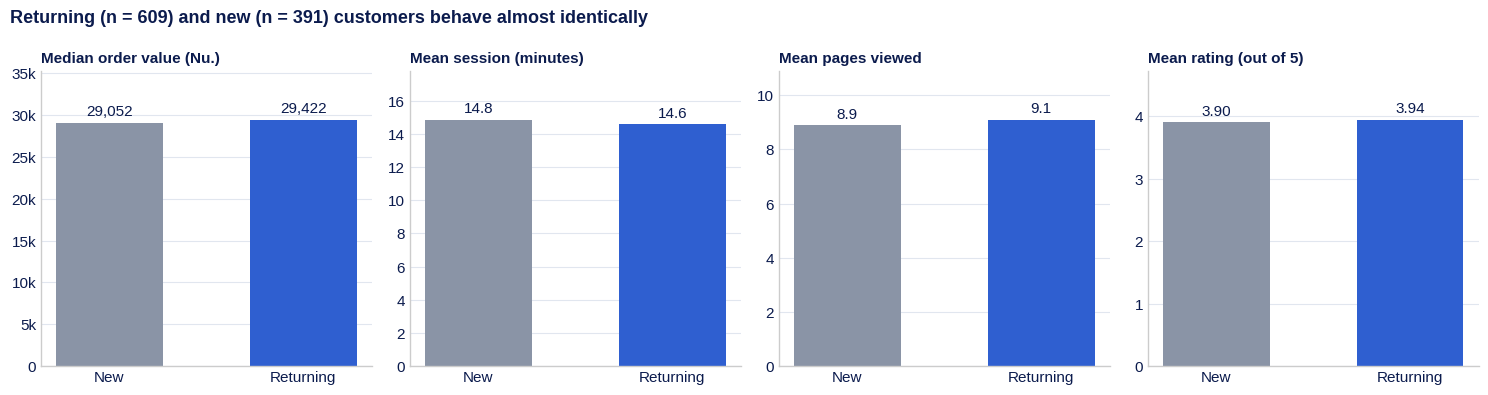

In [126]:
grp = (df.groupby('Is_Returning_Customer')
         .agg(median_value=(T, 'median'), session=('Session_Duration_Minutes', 'mean'),
              pages=('Pages_Viewed', 'mean'), rating=('Customer_Rating', 'mean'), n=(T, 'size')))
grp.index = ['New', 'Returning']
panels = [('median_value', 'Median order value (Nu.)', '{:,.0f}'), ('session', 'Mean session (minutes)', '{:.1f}'),
          ('pages', 'Mean pages viewed', '{:.1f}'), ('rating', 'Mean rating (out of 5)', '{:.2f}')]
fig, ax = plt.subplots(1, 4, figsize=(15, 4))
for a, (col, ttl, f) in zip(ax, panels):
    bars = a.bar(grp.index, grp[col], color=[GREY, BLUE], width=0.55)
    a.bar_label(bars, labels=[f.format(v) for v in grp[col]], padding=3)
    a.set_title(ttl, fontsize=11); a.set_ylim(0, grp[col].max() * 1.2); a.grid(axis='x', visible=False)
    if col == 'median_value': a.yaxis.set_major_formatter(MONEY)
fig.suptitle(f"Returning (n = {grp.loc['Returning','n']}) and new (n = {grp.loc['New','n']}) customers behave almost identically",
             x=0.01, ha='left', fontweight='bold', fontsize=13, color=INK)
finish(fig, 'fig09_returning_vs_new')

 On all four measures the two groups are nearly the same: median order value of Nu. 29,422 (returning) against Nu. 29,052 (new), nearly the same session length and pages viewed, and ratings of 3.94 and 3.90. Returning customers are the larger group (609 of 1,000 orders), but they do not spend or rate differently.

**9. Is browsing activity related to order value?**

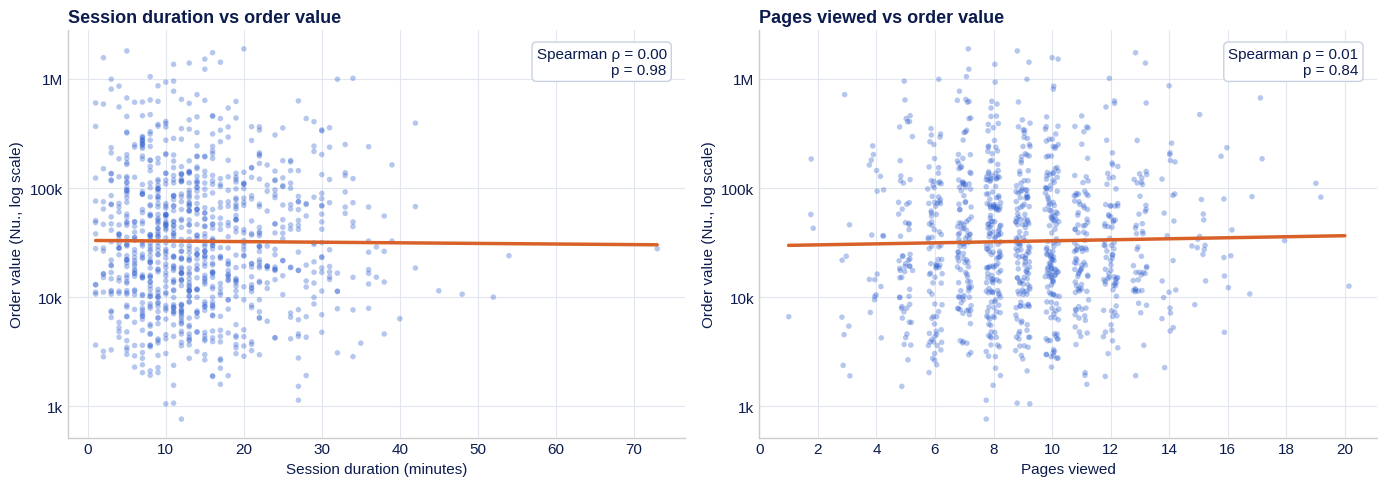

In [127]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
rng = np.random.default_rng(42)
for a, col, lab in [(ax[0], 'Session_Duration_Minutes', 'Session duration (minutes)'),
                    (ax[1], 'Pages_Viewed', 'Pages viewed')]:
    x = df[col].astype(float)
    xj = x + (rng.uniform(-0.25, 0.25, len(df)) if col == 'Pages_Viewed' else 0)   # jitter whole-number pages
    a.scatter(xj, df[T], s=16, alpha=0.35, color=BLUE, edgecolor='none')
    slope, intercept = np.polyfit(x, np.log10(df[T]), 1)                           # trend on the log scale
    xs = np.linspace(x.min(), x.max(), 100)
    a.plot(xs, 10 ** (intercept + slope * xs), color=ORANGE, lw=2.5)
    rho, p = stats.spearmanr(x, df[T])
    a.set_yscale('log'); a.yaxis.set_major_formatter(MONEY)
    a.set_xlabel(lab); a.set_ylabel('Order value (Nu., log scale)')
    a.set_title(f'{lab.split(" (")[0]} vs order value')
    if col == 'Pages_Viewed': a.set_xticks(range(0, 21, 2))
    a.text(0.97, 0.96, f"Spearman ρ = {f'{rho:.2f}'.replace('-0.00', '0.00')}\np = {p:.2f}", transform=a.transAxes, ha='right', va='top',
           fontsize=11, bbox=dict(boxstyle='round', fc='white', ec='#C9D1E0'))
finish(fig, 'fig10_engagement_scatter')

The cloud of points is flat and the orange trend line is almost horizontal for both measures (Spearman ρ = 0.00 for session length and 0.01 for pages viewed, both with p > 0.05). Long sessions and many page views do not lead to bigger orders. A flat relationship is a finding in itself: browsing effort does not predict spend here.

**10. Which variables move together?**

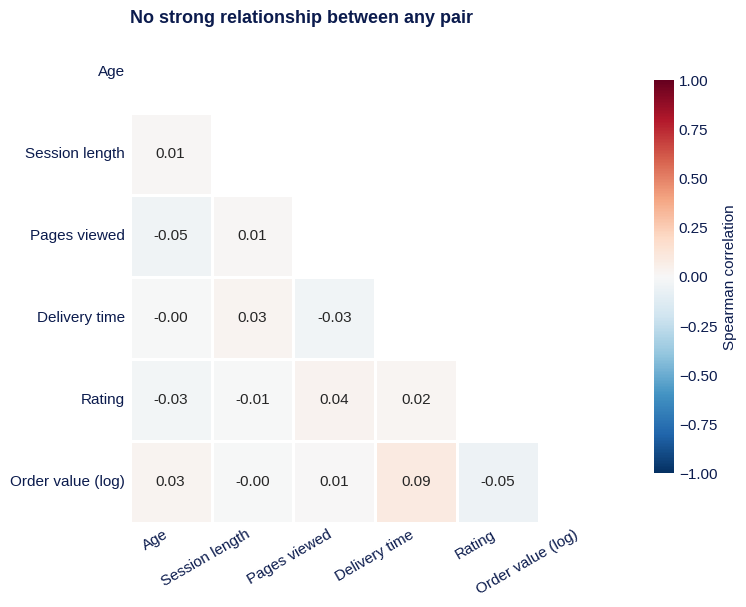

In [128]:
heat_cols = {'Age': 'Age', 'Session_Duration_Minutes': 'Session length', 'Pages_Viewed': 'Pages viewed',
             'Delivery_Time_Days': 'Delivery time', 'Customer_Rating': 'Rating', 'Log_Total': 'Order value (log)'}
corr = df[list(heat_cols)].corr(method='spearman').rename(index=heat_cols, columns=heat_cols)
mask = np.triu(np.ones_like(corr, dtype=bool), k=0)

fig, ax = plt.subplots(figsize=(8, 6.2))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, center=0,
            linewidths=1, linecolor='white', square=True, cbar_kws={'label': 'Spearman correlation', 'shrink': 0.8}, ax=ax)
ax.set_title('No strong relationship between any pair')
ax.grid(False); ax.tick_params(axis='x', rotation=30)
plt.setp(ax.get_xticklabels(), ha='right')
finish(fig, 'fig11_correlation_heatmap')

All coefficients lie between -0.05 and 0.09, so none of the variables is meaningfully correlated with another. Spearman correlation is used because order value is skewed. **Unit price, quantity and discount are left out on purpose:** order value is calculated from them (Total = Price × Quantity − Discount), so their correlation with it (for example Unit_Price ρ = 0.89) is arithmetic, not customer behaviour. This was the reason the earlier heatmap, which included them, was misleading.

**11. Which customer and product combinations earn the most?**

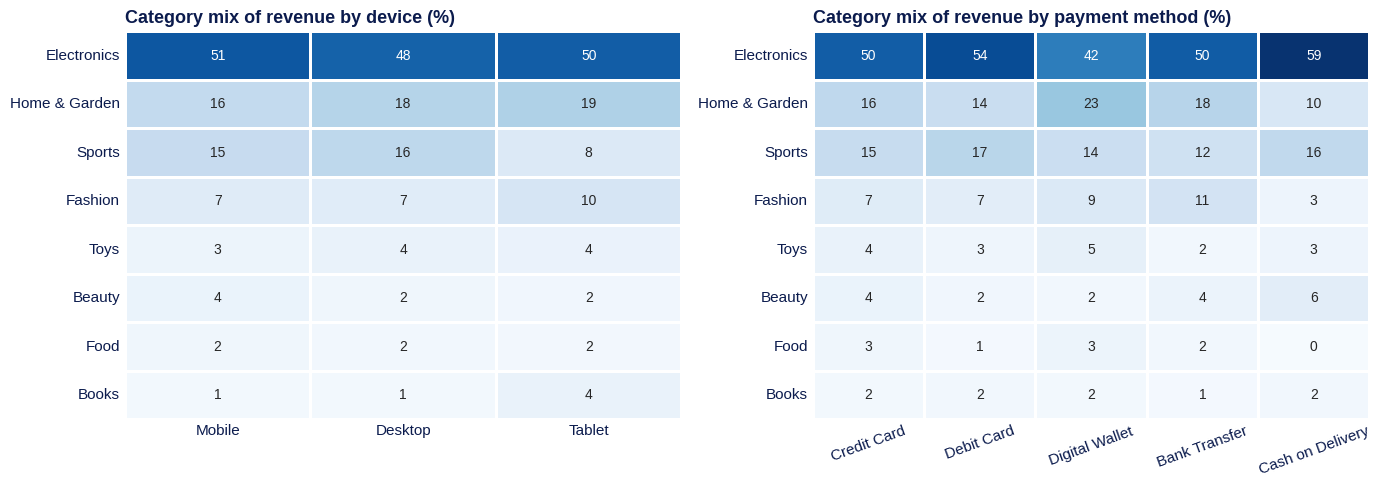

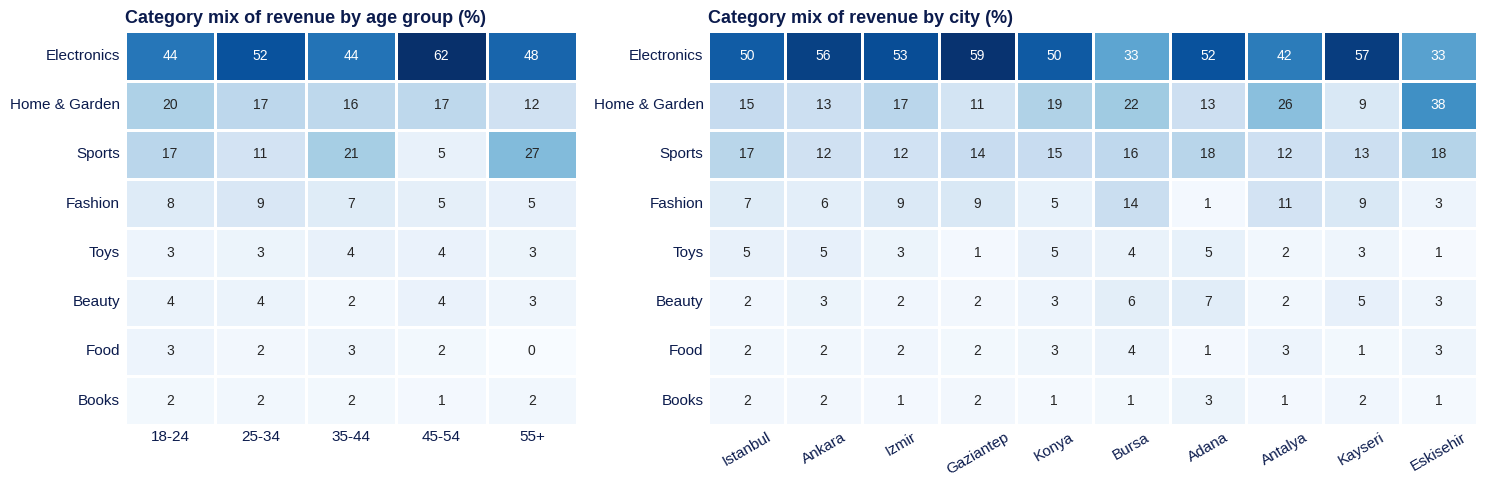

Revenue (Nu. millions) by category and age group


Age_Group,18-24,25-34,35-44,45-54,55+
Product_Category,,,,,
Electronics,7.4,14.1,11.5,10.0,3.4
Home & Garden,3.3,4.5,4.3,2.7,0.9
Sports,2.9,3.0,5.4,0.8,1.9
Fashion,1.3,2.5,1.9,0.9,0.4
Toys,0.5,0.9,1.2,0.7,0.3
Beauty,0.6,1.0,0.5,0.7,0.2
Food,0.5,0.5,0.8,0.3,0.0
Books,0.3,0.5,0.4,0.2,0.1


In [129]:
cat_order = df.groupby('Product_Category')[T].sum().sort_values(ascending=False).index

def rev_heat(ax, col, title, order=None, rot=0):
    ct = pd.crosstab(df['Product_Category'], df[col], values=df[T], aggfunc='sum').fillna(0)
    ct = ct.loc[cat_order] if order is None else ct.loc[cat_order, order]
    pct = ct / ct.sum() * 100                      # each column adds up to 100%
    sns.heatmap(pct, annot=True, fmt='.0f', cmap='Blues', vmin=0, vmax=60, linewidths=1, linecolor='white',
                cbar=False, ax=ax, annot_kws={'fontsize': 10})
    ax.set_title(title); ax.set_xlabel(''); ax.set_ylabel(''); ax.grid(False)
    ax.tick_params(axis='x', rotation=rot)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
rev_heat(ax[0], 'Device_Type', 'Category mix of revenue by device (%)', ['Mobile', 'Desktop', 'Tablet'])
rev_heat(ax[1], 'Payment_Method', 'Category mix of revenue by payment method (%)',
         ['Credit Card', 'Debit Card', 'Digital Wallet', 'Bank Transfer', 'Cash on Delivery'], rot=20)
finish(fig, 'fig12_crosstab_device_payment')

fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1, 1.7]})
rev_heat(ax[0], 'Age_Group', 'Category mix of revenue by age group (%)', AGE_ORDER)
city_order = df.groupby('City')[T].sum().sort_values(ascending=False).index.tolist()
rev_heat(ax[1], 'City', 'Category mix of revenue by city (%)', city_order, rot=30)
finish(fig, 'fig13_crosstab_age_city')

# Where does the money sit? Revenue (Nu. millions) for the largest category x age cells
cell = (pd.crosstab(df['Product_Category'], df['Age_Group'], values=df[T], aggfunc='sum') / 1e6).round(1)
print('Revenue (Nu. millions) by category and age group')
display(cell.loc[cat_order, AGE_ORDER])

 Each column adds up to 100%, so the colours show the category mix within a channel or segment. Electronics is the largest category in every device, payment-method and age-group column, earning between 42% and 62% of revenue there. By city it leads in 9 of 10 cities (Eskisehir is the exception, where Home & Garden leads). The single biggest customer–product block is Electronics bought by 25-34 year-olds (Nu. 14.1 million, 15.1% of all revenue). Differences between columns that rest on few orders (tablet, 55+, the smaller cities) are not reliable, and the chi-square test of device × payment in Part 3 (p = 0.37) found no association.

**12. How did sales change over time?**

Left out partial weeks ending 2023-01-01 (8 orders) and 2023-04-09 (6 orders)


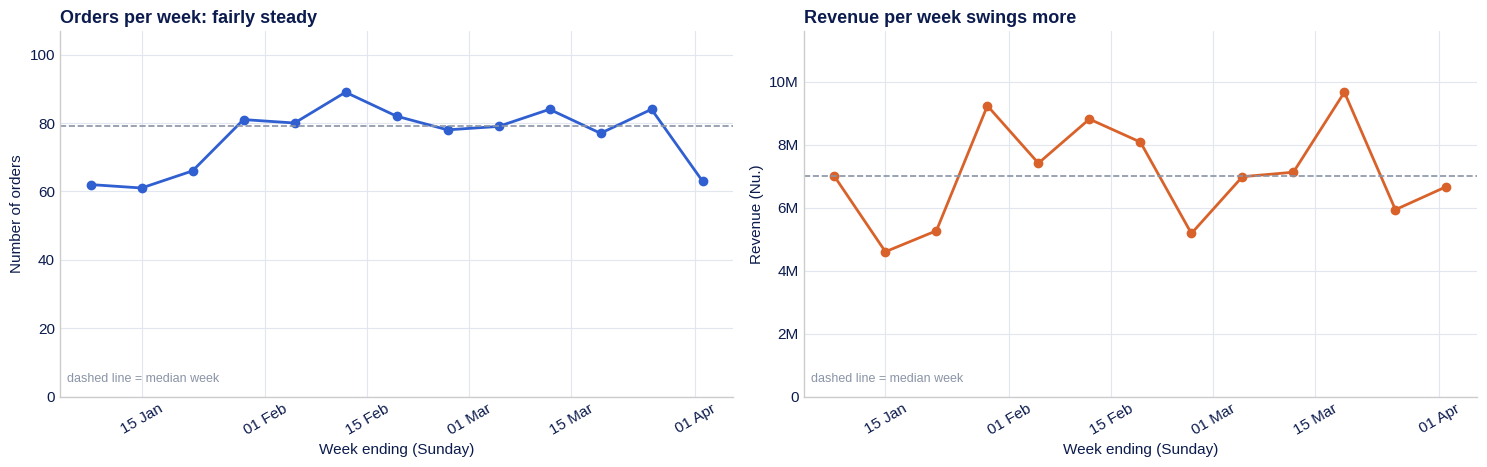

In [131]:
# Weeks run Monday-Sunday and are labelled by the Sunday that ends them.
# The first week (1 Jan only) and the last week (3 Apr only) are partial, so they are left out.
weekly = df.set_index('Date')[T].resample('W-SUN').agg(['count', 'sum']).rename(columns={'count': 'Orders', 'sum': 'Revenue'})
partial = [weekly.index[0], weekly.index[-1]]
wk = weekly.drop(partial)
print(f'Left out partial weeks ending {partial[0].date()} ({weekly.loc[partial[0], "Orders"]} orders) '
      f'and {partial[1].date()} ({weekly.loc[partial[1], "Orders"]} orders)')

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), sharex=True)
ax[0].plot(wk.index, wk['Orders'], color=BLUE, marker='o', lw=2)
ax[0].axhline(wk['Orders'].median(), color=GREY, ls='--', lw=1.2)
ax[0].set_title('Orders per week: fairly steady'); ax[0].set_ylabel('Number of orders'); ax[0].set_ylim(0, wk['Orders'].max() * 1.2)
ax[1].plot(wk.index, wk['Revenue'], color=ORANGE, marker='o', lw=2)
ax[1].axhline(wk['Revenue'].median(), color=GREY, ls='--', lw=1.2)
ax[1].set_title('Revenue per week swings more'); ax[1].set_ylabel('Revenue (Nu.)')
ax[1].yaxis.set_major_formatter(MONEY); ax[1].set_ylim(0, wk['Revenue'].max() * 1.2)
for a in ax:
    a.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
    a.set_xlabel('Week ending (Sunday)'); a.tick_params(axis='x', rotation=30)
    a.text(0.01, 0.04, 'dashed line = median week', transform=a.transAxes, color=GREY, fontsize=9)
finish(fig, 'fig14_weekly_trend')

The number of orders is fairly steady at about 61 to 89 a week, with a rise after January. Weekly revenue is much less stable (Nu. 4.6 million to 9.7 million) because a handful of very large Electronics orders can move a week's total. The data covers only 93 days, so these weekly movements show short-term variation, not seasonality.

**13. Key observations**
## 13. Key observations

Written in the format from the unit on communicating findings: the question, the evidence, and an honest limit.

| # | Observation | Evidence | Limit |
|---|---|---|---|
| 1 | **What customers buy drives revenue.** Electronics earns about half of all revenue from about one in eight orders. | Electronics: 49.8% of revenue, 12.6% of orders; top 3 categories 81.7% (Figure 4). | One 93-day window; association, not cause. |
| 2 | **Order value is highly skewed, so the median is the honest "typical" figure.** | Mean Nu. 93,104 against median Nu. 29,352; skewness 5.08, falling to 0.25 on the log scale (Figure 2). | The 112 high-value orders are real and were kept. |
| 3 | **Who the customer is, and how they browse, does not change spend.** | Medians are similar across age, device, gender and customer type (Figures 7–9); session length and pages viewed show ρ ≈ 0 with order value (Figure 10). | Small groups (tablet, 'Other' gender, 55+) are less reliable. |
| 4 | **Mobile and credit card dominate, and Istanbul leads.** | Mobile 55% of orders; credit card 39%; Istanbul 26.5% (Figures 5–6). | Shares of orders in this sample only. |
| 5 | **Orders are steady but revenue is volatile week to week.** | Orders 61–89 a week; revenue Nu. 4.6–9.7 million (Figure 14). | Only 13 complete weeks; no seasonal claim possible. |

**Limitations to state when presenting.** The 1,000 records are the first 1,000 by date, not a random sample. Each customer appears once, so repeat purchasing cannot be measured. Only completed orders are included, so abandoned sessions are unknown. Correlation and group differences describe association and do not prove cause.

H1 — Product Category → Order Value

In [125]:
categories = sorted(
    df_clean['Product_Category'].dropna().unique()
)

groups_cat = [
    df_clean[
        df_clean['Product_Category'] == category
    ]['Log_Total'].values
    for category in categories
]

f_stat, p_value = stats.f_oneway(*groups_cat)

print(f"F-statistic = {f_stat:.2f}")
print(f"p-value     = {p_value:.3e}")

if p_value < 0.05:
    print("Decision    : Reject H0 — significant")
else:
    print("Decision    : Fail to reject H0 — not significant")

F-statistic = 189.10
p-value     = 1.011e-177
Decision    : Reject H0 — significant


H2 — Session Engagement → Order Value

In [101]:
r_stat, p_value = stats.pearsonr(
    df_clean['Session_Duration_Minutes'],
    df_clean['Total_Amount']
)

print(f"Pearson r = {r_stat:.4f}")
print(f"p-value   = {p_value:.4f}")

if p_value < 0.05:
    print("Decision  : Reject H0 — significant")
else:
    print("Decision  : Fail to reject H0 — not significant")

Pearson r = -0.0378
p-value   = 0.2324
Decision  : Fail to reject H0 — not significant


H3 — Age Group → Order Value

In [102]:
age_groups = [
    '18-24',
    '25-34',
    '35-44',
    '45-54',
    '55+'
]

groups_age = [
    df_clean[
        df_clean['Age_Group'] == age
    ]['Log_Total'].values
    for age in age_groups
]

f_stat, p_value = stats.f_oneway(*groups_age)

print(f"F-statistic = {f_stat:.3f}")
print(f"p-value     = {p_value:.4f}")

if p_value < 0.05:
    print("Decision    : Reject H0 — significant")
else:
    print("Decision    : Fail to reject H0 — not significant")

F-statistic = 0.941
p-value     = 0.4395
Decision    : Fail to reject H0 — not significant


H4 — Returning vs New Customer

In [103]:
returning = df_clean[
    df_clean['Is_Returning_Customer'] == True
]['Log_Total']

new = df_clean[
    df_clean['Is_Returning_Customer'] == False
]['Log_Total']

t_stat, p_value = stats.ttest_ind(
    returning,
    new,
    equal_var=True
)

print(f"t-statistic = {t_stat:.3f}")
print(f"p-value     = {p_value:.4f}")

if p_value < 0.05:
    print("Decision    : Reject H0 — significant")
else:
    print("Decision    : Fail to reject H0 — not significant")

t-statistic = 0.364
p-value     = 0.7160
Decision    : Fail to reject H0 — not significant


H5 — Delivery Time → Customer Rating

In [104]:
rho_stat, p_value = stats.spearmanr(
    df_clean['Delivery_Time_Days'],
    df_clean['Customer_Rating']
)

print(f"Spearman rho = {rho_stat:.4f}")
print(f"p-value      = {p_value:.4f}")

if p_value < 0.05:
    print("Decision     : Reject H0 — significant")
else:
    print("Decision     : Fail to reject H0 — not significant")

Spearman rho = 0.0194
p-value      = 0.5397
Decision     : Fail to reject H0 — not significant


**PART 3 — Hypothesis summary**

In [105]:
# H1: Product Category → Order Value
f_stat_h1, p_h1 = stats.f_oneway(*groups_cat)

# H2: Session Duration → Order Value
r_h2, p_h2 = stats.pearsonr(
    df_clean['Session_Duration_Minutes'],
    df_clean['Total_Amount']
)

# H3: Age Group → Order Value
f_stat_h3, p_h3 = stats.f_oneway(*groups_age)

# H4: Returning vs New Customer → Order Value
t_stat_h4, p_h4 = stats.ttest_ind(
    returning,
    new
)

# H5: Delivery Time → Customer Rating
rho_h5, p_h5 = stats.spearmanr(
    df_clean['Delivery_Time_Days'],
    df_clean['Customer_Rating']
)

In [106]:
results = pd.DataFrame({
    'Hypothesis': ['H1', 'H2', 'H3', 'H4', 'H5'],
    'Test': [
        'ANOVA',
        'Pearson Correlation',
        'ANOVA',
        'Independent t-test',
        'Spearman Correlation'
    ],
    'Statistic': [
        f_stat_h1,
        r_h2,
        f_stat_h3,
        t_stat_h4,
        rho_h5
    ],
    'p-value': [
        p_h1,
        p_h2,
        p_h3,
        p_h4,
        p_h5
    ],
    'Result': [
        'Significant' if p_h1 < 0.05 else 'Not Significant',
        'Significant' if p_h2 < 0.05 else 'Not Significant',
        'Significant' if p_h3 < 0.05 else 'Not Significant',
        'Significant' if p_h4 < 0.05 else 'Not Significant',
        'Significant' if p_h5 < 0.05 else 'Not Significant'
    ]
})

display(results.round(4))

,Hypothesis,Test,Statistic,p-value,Result
0,H1,ANOVA,189.0969,0.0000,Significant
1,H2,Pearson Correlation,-0.0378,0.2324,Not Significant
2,H3,ANOVA,0.9408,0.4395,Not Significant
3,H4,Independent t-test,0.3639,0.7160,Not Significant
4,H5,Spearman Correlation,0.0194,0.5397,Not Significant


**Part Four-Research Questions**

In [107]:
# RQ1: Main purchasing patterns

print("Orders by category:")
print(df_clean['Product_Category'].value_counts())

print("\nOrders by payment method:")
print(df_clean['Payment_Method'].value_counts())

print("\nOrders by device:")
print(df_clean['Device_Type'].value_counts())

print("\nOrder value summary:")
print(df_clean['Total_Amount'].describe())

category_revenue = (
    df_clean
    .groupby('Product_Category', observed=True)['Total_Amount']
    .sum()
    .sort_values(ascending=False)
)

print("\nHighest-revenue category:")
print(category_revenue.index[0], round(category_revenue.iloc[0], 2))

Orders by category:
Product_Category
Books            144
Sports           138
Food             126
Electronics      126
Fashion          124
Beauty           121
Toys             114
Home & Garden    107
Name: count, dtype: int64

Orders by payment method:
Payment_Method
Credit Card         392
Debit Card          250
Digital Wallet      196
Bank Transfer       104
Cash on Delivery     58
Name: count, dtype: int64

Orders by device:
Device_Type
Mobile     551
Desktop    349
Tablet     100
Name: count, dtype: int64

Order value summary:
count    1.000000e+03
mean     9.310409e+04
std      1.966818e+05
min      7.607900e+02
25%      1.165913e+04
50%      2.935191e+04
75%      8.516047e+04
max      1.889628e+06
Name: Total_Amount, dtype: float64

Highest-revenue category:
Electronics 46409445.75


In [108]:
# RQ2: Distribution of order value

print("Skewness (raw):", round(df_clean['Total_Amount'].skew(), 2))
print("Skewness (log):", round(df_clean['Log_Total'].skew(), 2))

stat_raw, p_raw = stats.shapiro(df_clean['Total_Amount'])
stat_log, p_log = stats.shapiro(df_clean['Log_Total'])

print("\nShapiro-Wilk (raw): p =", p_raw)
print("Shapiro-Wilk (log): p =", p_log)

if p_raw < 0.05:
    print("\nRaw order value is NOT normal, so use log values or non-parametric tests.")

Skewness (raw): 5.08
Skewness (log): 0.25

Shapiro-Wilk (raw): p = 6.189818805311282e-48
Shapiro-Wilk (log): p = 0.0001369498343427759

Raw order value is NOT normal, so use log values or non-parametric tests.


In [109]:
# RQ3: Order value across age group, gender and device

# Age group
groups_age = [df_clean[df_clean['Age_Group'] == g]['Log_Total'] for g in df_clean['Age_Group'].unique()]
f_stat, p_age = stats.f_oneway(*groups_age)
print(f"Age group  : F = {f_stat:.3f}, p = {p_age:.4f}")

# Gender
groups_gender = [df_clean[df_clean['Gender'] == g]['Log_Total'] for g in df_clean['Gender'].unique()]
f_stat, p_gender = stats.f_oneway(*groups_gender)
print(f"Gender     : F = {f_stat:.3f}, p = {p_gender:.4f}")

# Device type
groups_device = [df_clean[df_clean['Device_Type'] == g]['Log_Total'] for g in df_clean['Device_Type'].unique()]
f_stat, p_device = stats.f_oneway(*groups_device)
print(f"Device type: F = {f_stat:.3f}, p = {p_device:.4f}")

for name, p in [('Age group', p_age), ('Gender', p_gender), ('Device', p_device)]:
    if p < 0.05:
        print(name, "-> Significant difference")
    else:
        print(name, "-> No significant difference")

Age group  : F = 0.941, p = 0.4395
Gender     : F = 0.457, p = 0.6333
Device type: F = 2.294, p = 0.1013
Age group -> No significant difference
Gender -> No significant difference
Device -> No significant difference


In [110]:
# RQ4: Returning vs new customers

compare = (
    df_clean
    .groupby('Is_Returning_Customer')
    .agg(
        avg_order_value=('Total_Amount', 'mean'),
        avg_session=('Session_Duration_Minutes', 'mean'),
        avg_pages=('Pages_Viewed', 'mean'),
        avg_rating=('Customer_Rating', 'mean')
    )
    .round(2)
)
print(compare)

returning = df_clean[df_clean['Is_Returning_Customer'] == True]
new = df_clean[df_clean['Is_Returning_Customer'] == False]

for col in ['Log_Total', 'Session_Duration_Minutes', 'Pages_Viewed', 'Customer_Rating']:
    t_stat, p_value = stats.ttest_ind(returning[col], new[col], equal_var=False)
    print(f"\n{col}: t = {t_stat:.3f}, p = {p_value:.4f}")
    if p_value < 0.05:
        print("Significant difference")
    else:
        print("No significant difference")

                       avg_order_value  avg_session  avg_pages  avg_rating
Is_Returning_Customer                                                     
False                         94534.72        14.84       8.89        3.90
True                          92185.57        14.58       9.09        3.94

Log_Total: t = 0.361, p = 0.7182
No significant difference

Session_Duration_Minutes: t = -0.452, p = 0.6514
No significant difference

Pages_Viewed: t = 1.123, p = 0.2618
No significant difference

Customer_Rating: t = 0.473, p = 0.6360
No significant difference


In [111]:
# RQ5: Session engagement vs order value

r_stat, p_value = stats.pearsonr(
    df_clean['Session_Duration_Minutes'],
    df_clean['Total_Amount']
)
rho_stat, p_rho = stats.spearmanr(
    df_clean['Session_Duration_Minutes'],
    df_clean['Total_Amount']
)

print(f"Pearson r    = {r_stat:.4f}, p = {p_value:.4f}")
print(f"Spearman rho = {rho_stat:.4f}, p = {p_rho:.4f}")

if p_rho < 0.05:
    print("Decision: Significant relationship")
else:
    print("Decision: No significant relationship")

# Pages viewed vs order value
rho_pages, p_pages = stats.spearmanr(df_clean['Pages_Viewed'], df_clean['Total_Amount'])
print(f"\nPages viewed vs order value: rho = {rho_pages:.4f}, p = {p_pages:.4f}")

Pearson r    = -0.0378, p = 0.2324
Spearman rho = -0.0006, p = 0.9841
Decision: No significant relationship

Pages viewed vs order value: rho = 0.0063, p = 0.8424


In [112]:
# RQ6: Delivery time vs customer rating

rho_stat, p_value = stats.spearmanr(
    df_clean['Delivery_Time_Days'],
    df_clean['Customer_Rating']
)

print(f"Spearman rho = {rho_stat:.4f}")
print(f"p-value      = {p_value:.4f}")

if p_value < 0.05:
    print("Decision: Significant relationship")
else:
    print("Decision: No significant relationship")

print("\nAverage delivery time by rating:")
print(df_clean.groupby('Customer_Rating')['Delivery_Time_Days'].mean().round(2))

Spearman rho = 0.0194
p-value      = 0.5397
Decision: No significant relationship

Average delivery time by rating:
Customer_Rating
1    6.77
2    5.79
3    6.17
4    6.38
5    6.43
Name: Delivery_Time_Days, dtype: float64


In [113]:
# RQ7: Revenue concentration

total_revenue = df_clean['Total_Amount'].sum()

# Category x Age group
revenue_age = df_clean.pivot_table(
    index='Product_Category',
    columns='Age_Group',
    values='Total_Amount',
    aggfunc='sum',
    observed=True
)
print("Revenue by Category and Age Group:")
print(revenue_age.round(0))

# Top customer-category combinations
combo = (
    df_clean
    .groupby(['Product_Category', 'Age_Group', 'Device_Type'], observed=True)['Total_Amount']
    .sum()
    .sort_values(ascending=False)
)
print("\nTop 5 combinations:")
print(combo.head(5).round(0))

# Concentration
cat_revenue = df_clean.groupby('Product_Category', observed=True)['Total_Amount'].sum().sort_values(ascending=False)
cat_share = (cat_revenue / total_revenue * 100).round(1)

print("\nRevenue share by category (%):")
print(cat_share)
print("\nTop 3 categories =", cat_share.head(3).sum().round(1), "% of total revenue")

Revenue by Category and Age Group:
Age_Group             18-24       25-34       35-44      45-54        55+
Product_Category                                                         
Beauty             623850.0    962689.0    518166.0   674637.0   218294.0
Books              272017.0    524896.0    400516.0   224163.0   145422.0
Electronics       7413511.0  14068658.0  11501514.0  9977902.0  3447860.0
Fashion           1308840.0   2505845.0   1867447.0   874940.0   371002.0
Food               527686.0    483630.0    752405.0   263491.0    12669.0
Home & Garden     3319361.0   4529978.0   4266211.0  2661972.0   866854.0
Sports            2926971.0   2972199.0   5426289.0   753180.0  1926773.0
Toys               544704.0    902527.0   1159788.0   654707.0   250522.0

Top 5 combinations:
Product_Category  Age_Group  Device_Type
Electronics       25-34      Mobile         7891542.0
                  45-54      Mobile         7588953.0
                  35-44      Mobile         7096443.0
 

In [114]:
# Save cleaned dataset as an Excel file

df_clean.to_excel(
    'cleaned_1000_ecommerce_BTN.xlsx',
    index=False
)

print("Excel file created successfully.")

Excel file created successfully.


In [115]:
from google.colab import files

files.download('cleaned_1000_ecommerce_BTN.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>